In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [5]:
df = pd.read_csv('1) iris.csv')
X = df.drop(columns=['species'])
y = df['species']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
k_values = [1, 3, 5, 7, 9, 11, 15]
accuracies = []

In [8]:
print("--- Comparing K Values ---")

--- Comparing K Values ---


In [9]:
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_k = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_k)
    accuracies.append(acc)
    print(f"K = {k:2d} | Test Accuracy: {acc:.4f}")

K =  1 | Test Accuracy: 0.9667
K =  3 | Test Accuracy: 0.9333
K =  5 | Test Accuracy: 0.9333
K =  7 | Test Accuracy: 0.9667
K =  9 | Test Accuracy: 0.9667
K = 11 | Test Accuracy: 0.9667
K = 15 | Test Accuracy: 0.9667


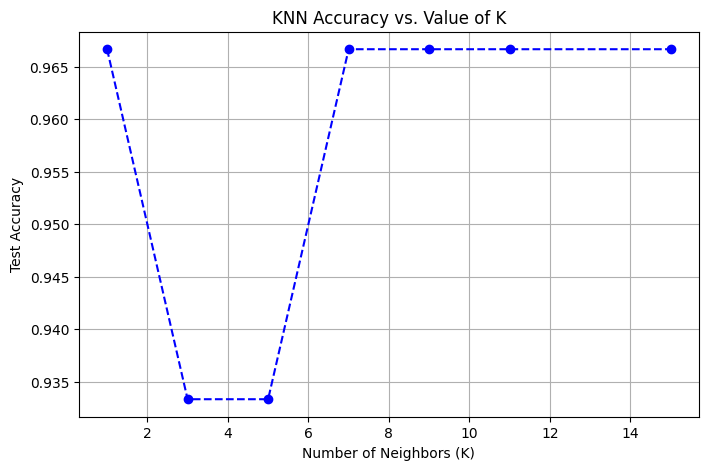

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='--', color='b')
plt.title('KNN Accuracy vs. Value of K')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.show()

In [11]:
best_k = 5
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
y_pred = knn_final.predict(X_test_scaled)

In [12]:
print(f"\n--- Final Model Metrics (K = {best_k}) ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred, average='macro'):.4f}")


--- Final Model Metrics (K = 5) ---
Accuracy : 0.9333
Precision: 0.9444
Recall   : 0.9333
F1 Score : 0.9327


In [13]:
print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))


--- Confusion Matrix ---
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


In [14]:
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred))


--- Detailed Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

